# Space Z에서 TensorBoard 사용하기

**TensorBoard는 학습 중 기록한 수치를 시간·step에 따라 보여주는 대시보드다.** PPO를 대신 학습시키지는 않는다.

| 저장물 | 담기는 내용 | 용도 |
| --- | --- | --- |
| `model.zip` | 저장 시점의 가중치·옵티마이저·누적 step | 모델 실행·추가 학습 |
| `events.out.tfevents...` | 학습하며 기록한 step·시각·지표 | TensorBoard 그래프 |
| `episodes.monitor.csv` | 종료된 에피소드의 보상·길이·점수·처치 | 원본 에피소드 수치 확인 |

이 노트북은 **기존 `train.py`와 환경 소스를 수정하지 않고** 별도로 짧은 학습을 실행한다. 기존 ZIP에서 과거 전체 로그를 복원하는 예제가 아니다.

읽는 순서: **준비 → 로그 경로 → 대시보드 → 짧은 학습 → 그래프 해석 → 추가 학습**.

## 1. 커널과 라이브러리 준비

VS Code에서 프로젝트 `.venv`를 커널로 선택한다. 패키지가 없으면 아래 명령을 그 가상환경의 터미널에서 실행하고 커널을 다시 시작한다.

```powershell
python -m pip install tensorboard stable-baselines3 matplotlib ipykernel
```

노트북 셀에서 설치할 때는 `%pip install tensorboard stable-baselines3 matplotlib ipykernel`을 쓴다. **TensorFlow는 설치할 필요가 없다.** PyTorch가 TensorBoard 로그를 기록한다.

In [1]:
from pathlib import Path
from datetime import datetime
import importlib.util
import os
import sys

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents)
                     if (p / "src/space_z/rl/environment.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("프로젝트 폴더 또는 study/에서 노트북을 실행하세요.")
if importlib.util.find_spec("tensorboard") is None:
    raise ImportError("현재 커널에 tensorboard가 없습니다. %pip install tensorboard 후 커널을 다시 시작하세요.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.environ.setdefault("PYGAME_HIDE_SUPPORT_PROMPT", "1")
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache/matplotlib"))

import torch
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.monitor import Monitor
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
from space_z.config import GameConfig, RewardConfig, EnvConfig
from space_z.rl import TankEnv, VectorObservation, ContinuousActionDecoder, RewardCalculator

torch.set_num_threads(1)  # 작은 MLP 예제에서 CPU 스레드 관리 비용을 줄인다.
print("커널 Python:", sys.executable)
print("프로젝트:", PROJECT_ROOT)

커널 Python: C:\LANG_CHAIN_2026\final-project\2026-10-12_game\.cache\windows-release-venv\Scripts\python.exe
프로젝트: C:\LANG_CHAIN_2026\final-project\2026-10-12_game


## 2. 로그와 모델 경로 정하기

- `tensorboard_log`: 여러 실험을 모아 놓는 **로그 상위 폴더**.
- `tb_log_name`: 해당 학습 실험의 이름. SB3가 뒤에 `_1`, `_2` 등을 붙여 run 폴더를 만든다.
- `total_timesteps`: 이번 예제에서 수집할 환경 step 수. 한 step은 기본 4게임 프레임이다.

예제는 1,024 step만 학습한다. 학습 성능을 판단하기 위한 분량이 아니다. 로그를 빨리 확인하도록 **이 노트북에서 만드는 환경의 에피소드 제한만 256 step**으로 설정한다. 프로젝트 기본값은 3,000이며 원본 설정은 바꾸지 않는다.

실행할 때마다 새 실험 이름을 만들고, 원래 모델 파일은 건드리지 않는다.

In [2]:
LOG_ROOT = PROJECT_ROOT / "logs/tensorboard_study"
RUN_NAME = "ppo_vector_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUTPUT_DIR = PROJECT_ROOT / "outputs/tensorboard_study" / RUN_NAME
TOTAL_STEPS = 1024
SEED = 42
SHOW_DASHBOARD = False  # 노트북 안에 대시보드를 띄우려면 True

assert isinstance(TOTAL_STEPS, int) and TOTAL_STEPS > 0
print("이벤트 로그 상위 폴더:", LOG_ROOT)
print("실험 이름:", RUN_NAME)
print("모델·CSV 출력 폴더:", OUTPUT_DIR)

이벤트 로그 상위 폴더: C:\LANG_CHAIN_2026\final-project\2026-10-12_game\logs\tensorboard_study
실험 이름: ppo_vector_20261028_123959_341939
모델·CSV 출력 폴더: C:\LANG_CHAIN_2026\final-project\2026-10-12_game\outputs\tensorboard_study\ppo_vector_20261028_123959_341939


## 3. TensorBoard 열기

학습 전 이 셀을 실행해 두면, 아래 학습 셀 실행 중에도 대시보드가 기록을 읽는다. 처음에는 이벤트 파일이 없어 빈 화면일 수 있다.

**방법 A — 노트북:** 위의 `SHOW_DASHBOARD=True`로 바꾸고 설정 셀과 다음 셀을 실행한다. `%load_ext tensorboard`는 IPython 확장을 불러오고, `%tensorboard`는 서버와 대시보드를 연다.

**방법 B — 별도 터미널:** 다음 셀이 출력하는 명령을 복사해서 실행한 뒤 브라우저에서 **http://127.0.0.1:6006** 을 연다. 터미널에서 `Ctrl+C`로 서버를 종료한다. 노트북 안의 화면이 안 보이면 이 방법을 사용한다.

두 방법 중 하나만 사용한다. 6006 포트가 이미 사용 중이면 6007처럼 다른 포트를 선택한다. 로그 생성과 TensorBoard 서버는 서로 별개라서, 학습 종료 후에도 저장된 로그를 다시 열 수 있다.

In [3]:
print("PowerShell에서 실행할 명령:")
print(f'& "{sys.executable}" -m tensorboard.main --logdir "{LOG_ROOT}" --host 127.0.0.1 --port 6006')
if SHOW_DASHBOARD:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is None:
        raise RuntimeError("노트북 커널에서 실행하거나 위의 터미널 명령을 사용하세요.")
    shell.run_line_magic("load_ext", "tensorboard")
    shell.run_line_magic("tensorboard", f'--logdir "{LOG_ROOT}" --host 127.0.0.1 --port 6006')
else:
    print("노트북 대시보드 실행 생략. SHOW_DASHBOARD=True로 켤 수 있습니다.")

PowerShell에서 실행할 명령:
& "C:\LANG_CHAIN_2026\final-project\2026-10-12_game\.cache\windows-release-venv\Scripts\python.exe" -m tensorboard.main --logdir "C:\LANG_CHAIN_2026\final-project\2026-10-12_game\logs\tensorboard_study" --host 127.0.0.1 --port 6006
노트북 대시보드 실행 생략. SHOW_DASHBOARD=True로 켤 수 있습니다.


## 4. 게임 점수·처치 수를 추가로 기록하기

`Monitor`는 종료된 에피소드의 보상과 길이를 모아 SB3에 전달한다. `info_keywords`로 `TankEnv.step()`의 `info`에 있는 점수·처치도 CSV와 `episode` 정보에 넣는다.

단, `info_keywords`를 지정하는 것만으로 점수·처치의 TensorBoard 그래프가 생기지는 않는다. 다음 콜백이 종료된 에피소드의 수치를 `game/episode_score`, `game/episode_kills`에 기록한다.

`record_mean()`은 다음 로그 출력까지 들어온 값을 평균 낸다. 콜백은 환경을 별도로 진행하거나 전투 이벤트를 소비하지 않는다.

In [4]:
class EpisodeMetricsCallback(BaseCallback):
    """에피소드가 끝나면 점수·처치 수를 다음 TensorBoard 로그에 기록한다."""

    def _on_step(self) -> bool:
        for info in self.locals["infos"]:
            episode = info.get("episode")
            if episode is not None:
                self.logger.record_mean("game/episode_score", episode["score"])
                self.logger.record_mean("game/episode_kills", episode["kills"])
        return True


def make_environment(csv_path=None):
    """공통 환경에 관찰·행동·보상을 연결하고 Monitor로 에피소드 기록을 붙인다."""
    environment = TankEnv(
        GameConfig(), VectorObservation(),
        ContinuousActionDecoder(enable_stat_upgrades=True, enable_evolution=True),
        RewardCalculator(RewardConfig()),
        env_config=EnvConfig(max_steps=256),
    )
    return Monitor(environment, filename=str(csv_path) if csv_path else None,
                   info_keywords=("score", "kills"))

## 5. 짧게 학습하고 로그 저장하기

핵심은 다음 두 인자다.

```python
model = PPO(..., tensorboard_log=str(LOG_ROOT))
model.learn(..., tb_log_name=RUN_NAME)
```

`verbose=1`은 터미널 출력을 켠다. **이것만으로 TensorBoard 이벤트 파일이 저장되지는 않는다.** `tensorboard_log`가 필요하다. 현재 프로젝트의 기존 `train.py`는 이 인자를 지정하지 않으므로 이 노트북에서 별도로 기록한다.

모델은 새로 만든다. 보상은 현재 `RewardConfig()` 기본값을 사용하므로, 기존 `train.py`에서 따로 지정한 보상과 다를 수 있다.

In [5]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
environment = make_environment(OUTPUT_DIR / "episodes.monitor.csv")
model = None
try:
    model = PPO(
        "MlpPolicy", environment,
        n_steps=256, batch_size=64,
        seed=SEED, device="cpu", verbose=1,
        tensorboard_log=str(LOG_ROOT),  # 이 인자가 TensorBoard 기록을 활성화한다.
    )
    model.learn(total_timesteps=TOTAL_STEPS, tb_log_name=RUN_NAME,
                callback=EpisodeMetricsCallback())
    RUN_DIR = Path(model.logger.dir)
    model.save(OUTPUT_DIR / "model.zip")
finally:
    environment.close()
    if model is not None and hasattr(model, "_logger"):
        model.logger.close()

print("실제 학습 step:", model.num_timesteps)
print("TensorBoard run:", RUN_DIR)
print("모델:", OUTPUT_DIR / "model.zip")
print("에피소드 CSV:", OUTPUT_DIR / "episodes.monitor.csv")

Using cpu device
Wrapping the env in a DummyVecEnv.


Logging to C:\LANG_CHAIN_2026\final-project\2026-10-12_game\logs\tensorboard_study\ppo_vector_20261028_123959_341939_1


---------------------------------
| game/              |          |
|    episode_kills   | 0        |
|    episode_score   | 0        |
| rollout/           |          |
|    ep_len_mean     | 256      |
|    ep_rew_mean     | -1.04    |
| time/              |          |
|    fps             | 207      |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 256      |
---------------------------------


-----------------------------------------
| game/                   |             |
|    episode_kills        | 0           |
|    episode_score        | 0           |
| rollout/                |             |
|    ep_len_mean          | 256         |
|    ep_rew_mean          | -1.05       |
| time/                   |             |
|    fps                  | 200         |
|    iterations           | 2           |
|    time_elapsed         | 2           |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.010190574 |
|    clip_fraction        | 0.0852      |
|    clip_range           | 0.2         |
|    entropy_loss         | -7.09       |
|    explained_variance   | 0.0926      |
|    learning_rate        | 0.0003      |
|    loss                 | -0.0416     |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0178     |
|    std                  | 0.996       |
|    value_loss           | 0.0218

-----------------------------------------
| game/                   |             |
|    episode_kills        | 0           |
|    episode_score        | 0           |
| rollout/                |             |
|    ep_len_mean          | 256         |
|    ep_rew_mean          | -1.01       |
| time/                   |             |
|    fps                  | 197         |
|    iterations           | 3           |
|    time_elapsed         | 3           |
|    total_timesteps      | 768         |
| train/                  |             |
|    approx_kl            | 0.014736601 |
|    clip_fraction        | 0.159       |
|    clip_range           | 0.2         |
|    entropy_loss         | -7.07       |
|    explained_variance   | -1.36       |
|    learning_rate        | 0.0003      |
|    loss                 | -0.0211     |
|    n_updates            | 20          |
|    policy_gradient_loss | -0.0243     |
|    std                  | 0.995       |
|    value_loss           | 0.0059

-----------------------------------------
| game/                   |             |
|    episode_kills        | 0           |
|    episode_score        | 0           |
| rollout/                |             |
|    ep_len_mean          | 256         |
|    ep_rew_mean          | -6.34       |
| time/                   |             |
|    fps                  | 196         |
|    iterations           | 4           |
|    time_elapsed         | 5           |
|    total_timesteps      | 1024        |
| train/                  |             |
|    approx_kl            | 0.017882505 |
|    clip_fraction        | 0.155       |
|    clip_range           | 0.2         |
|    entropy_loss         | -7.07       |
|    explained_variance   | 0.731       |
|    learning_rate        | 0.0003      |
|    loss                 | -0.051      |
|    n_updates            | 30          |
|    policy_gradient_loss | -0.017      |
|    std                  | 0.993       |
|    value_loss           | 0.0039

실제 학습 step: 1024
TensorBoard run: C:\LANG_CHAIN_2026\final-project\2026-10-12_game\logs\tensorboard_study\ppo_vector_20261028_123959_341939_1
모델: C:\LANG_CHAIN_2026\final-project\2026-10-12_game\outputs\tensorboard_study\ppo_vector_20261028_123959_341939\model.zip
에피소드 CSV: C:\LANG_CHAIN_2026\final-project\2026-10-12_game\outputs\tensorboard_study\ppo_vector_20261028_123959_341939\episodes.monitor.csv


## 6. 그래프에서 먼저 볼 항목

대시보드의 **Time Series / Scalars**에서 지표를 선택한다. 버전에 따라 탭 이름이 다를 수 있다.

| 태그 | 의미 | 읽는 방법 |
| --- | --- | --- |
| `rollout/ep_rew_mean` | 최근 최대 100개 종료 에피소드의 평균 보상 | 같은 게임·보상 설정에서 추세를 비교한다. loss가 아니다. |
| `rollout/ep_len_mean` | 최근 에피소드의 평균 환경 step 수 | 생존 증가일 수도 있고 시간 제한에 도달한 것일 수도 있다. |
| `game/episode_score` | 콜백이 기록한 종료 에피소드 게임 점수 | 실제 게임 성과를 보상과 함께 본다. |
| `game/episode_kills` | 콜백이 기록한 종료 에피소드 처치 수 | 처치 행동이 나타나는지 본다. |
| `train/value_loss` | 가치 예측과 학습 목표 사이의 제곱 오차 | 보상 크기에 영향을 받는다. 작다는 이유만으로 좋은 정책은 아니다. |
| `train/explained_variance` | 가치 예측의 설명력 | 1에 가까우면 잘 설명하고, 0은 거의 설명하지 못하며 음수일 수도 있다. |
| `train/policy_gradient_loss` | 정책 갱신 목적의 손실 | 부호나 감소만으로 플레이 실력 향상을 판단하지 않는다. |
| `train/entropy_loss` | 정책 분포의 엔트로피에 음수를 붙인 값 | 탐색 정도를 이해하는 보조 지표다. |
| `train/approx_kl` | 갱신 전후 정책 분포 차이의 근삿값 | 정책이 얼마나 변하는지 본다. |
| `train/clip_fraction` | PPO 비율이 clipping 범위를 벗어난 비율 | 0~1 값이며, 무조건 높거나 낮은 것이 목표는 아니다. |
| `time/fps` | 학습 중 초당 수집한 환경 step 수 | 게임 화면 FPS나 GPU 사용률이 아니다. |

- 가로축의 **Step**이 누적 환경 step이다. `time/total_timesteps`라는 그래프를 따로 찾을 필요는 없다. SB3는 그 값을 기본적으로 TensorBoard scalar에서 제외한다.
- 첫 rollout에는 아직 정책 갱신 지표가 없을 수 있다. `rollout/ep_*`는 에피소드가 끝난 뒤 생긴다.
- `Smoothing`은 표시를 부드럽게 만들 뿐 원본 값을 바꾸지 않는다. 보상 평균에 추가 smoothing이 적용될 수 있으므로 원본 점도 확인한다.
- **학습 곡선과 독립 평가 곡선은 다르다.** 이 예제에는 별도 평가 환경의 `eval/mean_reward`는 없다. 정책 성능 비교에는 고정 시드 평가도 함께 사용한다.
- 모델을 다시 실행하면 왼쪽 run 목록에서 실험을 선택해 곡선을 겹쳐 볼 수 있다. 설정이 다른 보상을 그대로 비교하지 않는다.

## 7. 이벤트가 실제 저장됐는지 확인하기

이 셀은 TensorBoard가 읽는 이벤트 파일을 Python으로 읽는다. `scalars: 0`은 저장된 scalar를 샘플링 제한 없이 모두 읽으라는 뜻이다. 기존 ZIP이 아니라 **방금 기록한 로그 파일**에서 읽는다.

학습이 끝나도 이벤트 파일은 남는다. 아래 assert는 기본 지표와 사용자 지표가 저장됐는지 확인한다.

SB3 기본 기록 순서를 그대로 사용한다. `train/*`는 직전 정책 갱신에서 계산한 수치가 다음 rollout의 로그 출력 때 기록되므로, 모든 값이 매 환경 step마다 저장되지는 않는다.

In [6]:
event_files = sorted(RUN_DIR.glob("events.out.tfevents.*"))
assert event_files, "TensorBoard 이벤트 파일이 생성되지 않았습니다."
for path in event_files:
    print(path.name, f"({path.stat().st_size:,} bytes)")

accumulator = EventAccumulator(str(RUN_DIR), size_guidance={"scalars": 0})
accumulator.Reload()
scalar_tags = accumulator.Tags()["scalars"]
required = {"rollout/ep_rew_mean", "train/value_loss", "train/explained_variance",
            "game/episode_score", "game/episode_kills"}
assert required.issubset(scalar_tags), f"누락된 태그: {required - set(scalar_tags)}"
assert all(event.step <= model.num_timesteps for tag in scalar_tags for event in accumulator.Scalars(tag))
print("\n저장된 scalar 태그:")
print("\n".join(scalar_tags))
print("\n보상 기록: (환경 step, 평균 보상)")
print([(event.step, round(event.value, 3)) for event in accumulator.Scalars("rollout/ep_rew_mean")])

events.out.tfevents.1793158803.HRW29.115216.0 (2,882 bytes)

저장된 scalar 태그:
game/episode_kills
game/episode_score
rollout/ep_len_mean
rollout/ep_rew_mean
time/fps
train/approx_kl
train/clip_fraction
train/clip_range
train/entropy_loss
train/explained_variance
train/learning_rate
train/loss
train/policy_gradient_loss
train/std
train/value_loss

보상 기록: (환경 step, 평균 보상)
[(256, -1.043), (512, -1.051), (768, -1.008), (1024, -6.342)]


### 대시보드를 열지 않아도 값 확인하기

아래는 동일한 이벤트 수치를 Matplotlib으로 그린 간단한 미리보기다. TensorBoard의 run 선택·smoothing·실시간 갱신 기능은 위의 대시보드에서 사용한다. 1,024 step 예제의 그래프 모양으로 학습 성패를 판단하지 않는다.

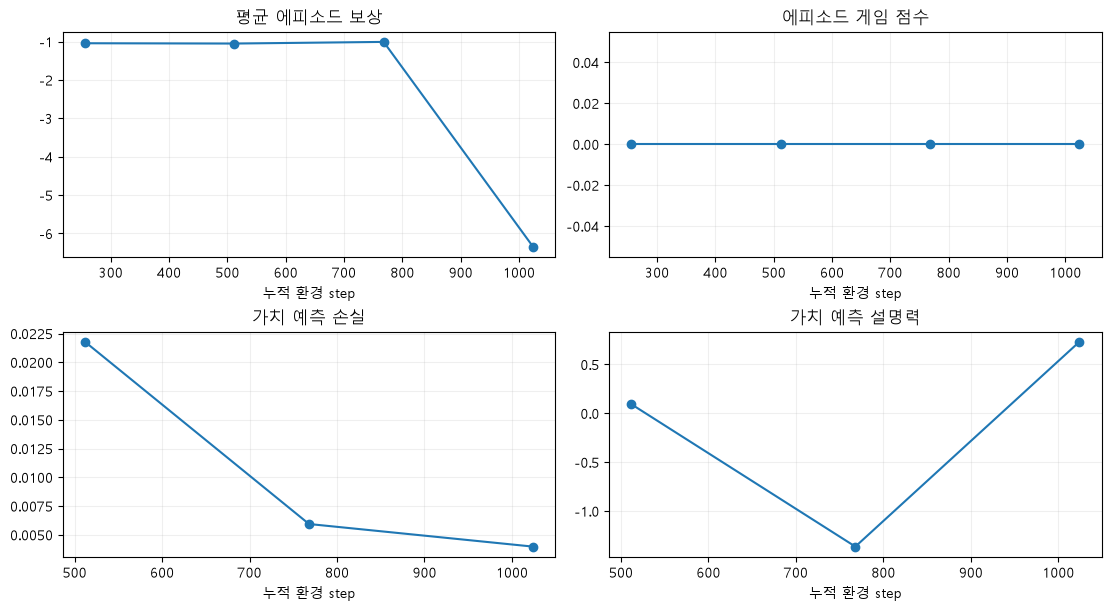

In [7]:
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from matplotlib import font_manager

font = Path("C:/Windows/Fonts/malgun.ttf")
if font.is_file():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(font)).get_name()
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(2, 2, figsize=(11, 6), layout="constrained")
for ax, (tag, title) in zip(axes.flat, [
    ("rollout/ep_rew_mean", "평균 에피소드 보상"),
    ("game/episode_score", "에피소드 게임 점수"),
    ("train/value_loss", "가치 예측 손실"),
    ("train/explained_variance", "가치 예측 설명력"),
]):
    events = accumulator.Scalars(tag)
    ax.plot([e.step for e in events], [e.value for e in events], marker="o")
    ax.set(title=title, xlabel="누적 환경 step")
    ax.grid(alpha=.2)
plt.show()

## 8. 추가 학습하면서 로그 이어 쓰기

저장 모델을 불러올 때도 `tensorboard_log`를 지정할 수 있다. **같은 로그 상위 폴더·같은 `tb_log_name`·`reset_num_timesteps=False`**를 사용하면 SB3가 해당 이름의 가장 최근 run 폴더에 이어 기록한다. 과거 run 폴더도 보존돼 있어야 한다.

다음 셀은 기본적으로 실행하지 않는다. `RUN_RESUME=True`로 바꾸면 방금 저장한 예제 모델에 256 step을 추가하고 `model_continued.zip`으로 저장한다. 원본 `model.zip`은 보존한다.

예전 ZIP만 있고 당시 이벤트 파일이 없다면, 누적 step 번호를 이어 쓰더라도 **새로 학습한 구간만** 기록된다. 과거 곡선이 만들어지지는 않는다.

In [8]:
RUN_RESUME = False
if RUN_RESUME:
    resume_environment = make_environment()
    resumed = None
    try:
        resumed = PPO.load(OUTPUT_DIR / "model.zip", env=resume_environment,
                           device="cpu", tensorboard_log=str(LOG_ROOT))
        before = resumed.num_timesteps
        resumed.learn(total_timesteps=256, tb_log_name=RUN_NAME,
                      reset_num_timesteps=False, callback=EpisodeMetricsCallback())
        assert resumed.num_timesteps == before + 256
        assert Path(resumed.logger.dir) == RUN_DIR
        resumed.save(OUTPUT_DIR / "model_continued.zip")
        print("누적 step:", before, "→", resumed.num_timesteps)
        print("이어 쓴 로그:", resumed.logger.dir)
    finally:
        resume_environment.close()
        if resumed is not None and hasattr(resumed, "_logger"):
            resumed.logger.close()
else:
    print("추가 학습 생략. RUN_RESUME=True로 바꾸면 실행합니다.")

추가 학습 생략. RUN_RESUME=True로 바꾸면 실행합니다.


## 9. 현재 프로젝트에 적용할 때 기억할 것

현재 [train.py](../src/space_z/rl/train.py)에 필요한 연결은 다음과 같다. 이 노트북에서 해당 파일을 수정하지는 않는다.

```python
# 새 모델 또는 PPO.load()에 로그 상위 경로를 전달한다.
model = PPO(..., tensorboard_log="logs/ppo")
# model = PPO.load(zip_path, env=environment, tensorboard_log="logs/ppo")

# 새 학습에는 새 이름, 이어 쓰려면 기존 이름과 reset_num_timesteps=False를 사용한다.
model.learn(total_timesteps=100_000, tb_log_name="experiment_name")
```

- **ZIP과 이벤트 로그를 함께 보관**해야 모델과 학습 곡선을 나중에 확인할 수 있다.
- TensorBoard 로그는 자동으로 중간 모델 가중치를 보존하지 않는다. 과거 모델도 필요하면 별도로 checkpoint를 저장해야 한다.
- 로그 생성 후 서버에서 비어 보이면 `--logdir` 경로, run 선택, 새로 고침을 확인한다. 보상 그래프만 없다면 에피소드가 아직 끝나지 않았을 수도 있다.
- 서버를 꺼도 로그는 지워지지 않는다. 커널을 다시 시작한 뒤에도 같은 `--logdir`로 다시 열 수 있다.

이 예제의 생성 위치:

```text
logs/tensorboard_study/<실험 이름>_1/events.out.tfevents...  # 그래프 데이터
outputs/tensorboard_study/<실험 이름>/model.zip            # 예제 학습 모델
outputs/tensorboard_study/<실험 이름>/episodes.monitor.csv # 에피소드 수치
```